# Task 3 - Predikcija kategorije proizvoda

## Cilj projekta

Cilj projekta je razvoj modela mašinskog učenja koji na osnovu naziva proizvoda automatski predlaže odgovarajuću kategoriju.

Tok rada:
- učitavanje i analiza podataka
- čišćenje podataka
- priprema i inženjering karakteristika
- podela na trening i test skup
- TF-IDF vektorizacija teksta
- poređenje više modela
- evaluacija najboljeg modela
- čuvanje finalnog modela
- testiranje novih proizvoda

In [29]:
import pandas as pd

# Ucitavanje skupa podataka
df = pd.read_csv("products.csv")

print("Prvih 5 redova:")
display(df.head())

print("\nDimenzije dataseta:")
print(df.shape)

print("\nNazivi kolona:")
print(df.columns.tolist())

print("\nNedostajuce vrednosti:")
print(df.isna().sum())

print("\nTipovi podataka:")
print(df.dtypes)

Prvih 5 redova:


,product ID,Product Title,Merchant ID,Category Label,_Product Code,Number_of_Views,Merchant Rating,Listing Date
0,1,apple iphone 8 plus 64gb silver,1,Mobile Phones,QA-2276-XC,860.0,2.5,5/10/2024
1,2,apple iphone 8 plus 64 gb spacegrau,2,Mobile Phones,KA-2501-QO,3772.0,4.8,12/31/2024
2,3,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...,3,Mobile Phones,FP-8086-IE,3092.0,3.9,11/10/2024
3,4,apple iphone 8 plus 64gb space grey,4,Mobile Phones,YI-0086-US,466.0,3.4,5/2/2022
4,5,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,5,Mobile Phones,NZ-3586-WP,4426.0,1.6,4/12/2023



Dimenzije dataseta:
(35311, 8)

Nazivi kolona:
['product ID', 'Product Title', 'Merchant ID', ' Category Label', '_Product Code', 'Number_of_Views', 'Merchant Rating', ' Listing Date  ']

Nedostajuce vrednosti:
product ID           0
Product Title      172
Merchant ID          0
 Category Label     44
_Product Code       95
Number_of_Views     14
Merchant Rating    170
 Listing Date       59
dtype: int64

Tipovi podataka:
product ID           int64
Product Title          str
Merchant ID          int64
 Category Label        str
_Product Code          str
Number_of_Views    float64
Merchant Rating    float64
 Listing Date          str
dtype: object


In [30]:
# ------------------------------------------------------------
# Ciscenje naziva kolona
# ------------------------------------------------------------

# Uklanjamo razmake sa pocetka i kraja naziva kolona
df.columns = df.columns.str.strip()

# Preimenujemo kolone da budu jednostavnije za rad
df = df.rename(columns={
    "product ID": "product_id",
    "Product Title": "product_title",
    "Merchant ID": "merchant_id",
    "Category Label": "category",
    "_Product Code": "product_code",
    "Number_of_Views": "number_of_views",
    "Merchant Rating": "merchant_rating",
    "Listing Date": "listing_date"
})

print("Nazivi kolona nakon ciscenja:")
print(df.columns.tolist())

print("\nBroj jedinstvenih kategorija:")
print(df["category"].nunique(dropna=True))

print("\nNajcesce kategorije:")
print(df["category"].value_counts(dropna=False).head(25))

Nazivi kolona nakon ciscenja:
['product_id', 'product_title', 'merchant_id', 'category', 'product_code', 'number_of_views', 'merchant_rating', 'listing_date']

Broj jedinstvenih kategorija:
13

Najcesce kategorije:
category
Fridge Freezers     5495
Washing Machines    4036
Mobile Phones       4020
CPUs                3771
TVs                 3564
Fridges             3457
Dishwashers         3418
Digital Cameras     2696
Microwaves          2338
Freezers            2210
fridge               123
CPU                   84
Mobile Phone          55
NaN                   44
Name: count, dtype: int64


In [31]:
# ------------------------------------------------------------
# Standardizacija kategorija i uklanjanje praznih redova
# ------------------------------------------------------------

# Uklanjamo proizvode kojima nedostaje naziv ili kategorija
df_clean = df.dropna(
    subset=["product_title", "category"]
).copy()

# Uklanjamo nepotrebne razmake
df_clean["product_title"] = (
    df_clean["product_title"]
    .astype(str)
    .str.strip()
)

df_clean["category"] = (
    df_clean["category"]
    .astype(str)
    .str.strip()
)

# Spajamo iste kategorije koje su bile razlicito napisane
category_mapping = {
    "fridge": "Fridges",
    "CPU": "CPUs",
    "Mobile Phone": "Mobile Phones"
}

df_clean["category"] = df_clean["category"].replace(
    category_mapping
)

# Uklanjamo eventualne prazne naslove
df_clean = df_clean[
    df_clean["product_title"] != ""
].copy()

print("Dimenzije nakon ciscenja:")
print(df_clean.shape)

print("\nBroj kategorija nakon standardizacije:")
print(df_clean["category"].nunique())

print("\nRaspodela kategorija:")
print(df_clean["category"].value_counts())

Dimenzije nakon ciscenja:
(35096, 8)

Broj kategorija nakon standardizacije:
10

Raspodela kategorija:
category
Fridge Freezers     5470
Mobile Phones       4057
Washing Machines    4015
CPUs                3831
Fridges             3559
TVs                 3541
Dishwashers         3405
Digital Cameras     2689
Microwaves          2328
Freezers            2201
Name: count, dtype: int64


In [32]:
# ------------------------------------------------------------
# Provera duplikata i konfliktnih kategorija
# ------------------------------------------------------------

# Koliko redova ima naslov koji se pojavljuje vise puta?
duplicate_rows = df_clean[
    df_clean.duplicated(
        subset=["product_title"],
        keep=False
    )
]

print("Broj redova sa ponovljenim naslovom:")
print(len(duplicate_rows))

print("\nBroj jedinstvenih naslova koji se ponavljaju:")
print(duplicate_rows["product_title"].nunique())


# Proveravamo da li isti naslov nekad ima vise razlicitih kategorija
title_category_counts = (
    df_clean
    .groupby("product_title")["category"]
    .nunique()
)

conflicting_titles = title_category_counts[
    title_category_counts > 1
]

print("\nBroj naslova koji imaju konfliktne kategorije:")
print(len(conflicting_titles))

# Prikaz nekoliko primera ako postoje
if len(conflicting_titles) > 0:
    conflict_examples = df_clean[
        df_clean["product_title"].isin(
            conflicting_titles.index
        )
    ].sort_values("product_title")

    display(
        conflict_examples[
            ["product_title", "category"]
        ].head(20)
    )

Broj redova sa ponovljenim naslovom:
7424

Broj jedinstvenih naslova koji se ponavljaju:
3152

Broj naslova koji imaju konfliktne kategorije:
2


,product_title,category
31700,blomberg kgm9550 fridge freezer,Fridge Freezers
35196,blomberg kgm9550 fridge freezer,Fridges
23671,bosch kur15a50gb integrated undercounter fridge,Washing Machines
31728,bosch kur15a50gb integrated undercounter fridge,Fridges


In [33]:
# ------------------------------------------------------------
# Uklanjanje konfliktnih naslova i duplikata
# ------------------------------------------------------------

# Uklanjamo naslove koji imaju vise razlicitih kategorija
df_model = df_clean[
    ~df_clean["product_title"].isin(
        conflicting_titles.index
    )
].copy()

# Za naslove koji se ponavljaju u istoj kategoriji
# zadrzavamo samo jedan zapis
df_model = df_model.drop_duplicates(
    subset=["product_title"],
    keep="first"
).copy()

print("Dimenzije nakon uklanjanja konflikata i duplikata:")
print(df_model.shape)

print("\nBroj jedinstvenih naslova:")
print(df_model["product_title"].nunique())

print("\nBroj kategorija:")
print(df_model["category"].nunique())

print("\nRaspodela kategorija:")
print(df_model["category"].value_counts())

Dimenzije nakon uklanjanja konflikata i duplikata:
(30822, 8)

Broj jedinstvenih naslova:
30822

Broj kategorija:
10

Raspodela kategorija:
category
Fridge Freezers     4808
Mobile Phones       3662
Washing Machines    3402
TVs                 3275
Fridges             3188
CPUs                3043
Dishwashers         3042
Digital Cameras     2405
Microwaves          2094
Freezers            1903
Name: count, dtype: int64


In [34]:
# ------------------------------------------------------------
# FEATURE ENGINEERING
# ------------------------------------------------------------

import re

# Broj karaktera u naslovu
df_model["title_length"] = (
    df_model["product_title"]
    .str.len()
)

# Broj reci u naslovu
df_model["word_count"] = (
    df_model["product_title"]
    .str.split()
    .str.len()
)

# Broj cifara u naslovu
df_model["digit_count"] = (
    df_model["product_title"]
    .str.count(r"\d")
)

# Broj specijalnih znakova
df_model["special_char_count"] = (
    df_model["product_title"]
    .str.count(r"[^A-Za-z0-9\s]")
)

# Duzina najduze reci u naslovu
df_model["longest_word_length"] = (
    df_model["product_title"]
    .apply(
        lambda text: max(
            len(word)
            for word in text.split()
        )
    )
)

print("Nove karakteristike:")
print([
    "title_length",
    "word_count",
    "digit_count",
    "special_char_count",
    "longest_word_length"
])

print("\nOsnovna statistika:")
display(
    df_model[
        [
            "title_length",
            "word_count",
            "digit_count",
            "special_char_count",
            "longest_word_length"
        ]
    ].describe()
)

Nove karakteristike:
['title_length', 'word_count', 'digit_count', 'special_char_count', 'longest_word_length']

Osnovna statistika:


,title_length,word_count,digit_count,special_char_count,longest_word_length
count,30822.000000,30822.000000,30822.000000,30822.000000,30822.000000
mean,52.761242,8.649731,6.816624,0.285705,9.785186
std,22.622348,4.215699,4.433567,0.624757,2.639525
min,5.000000,1.000000,0.000000,0.000000,2.000000
25%,38.000000,6.000000,4.000000,0.000000,8.000000
50%,51.000000,8.000000,6.000000,0.000000,10.000000
75%,65.000000,11.000000,9.000000,0.000000,11.000000
max,200.000000,37.000000,54.000000,9.000000,33.000000


In [35]:
feature_summary = (
    df_model
    .groupby("category")[
        [
            "title_length",
            "word_count",
            "digit_count",
            "special_char_count",
            "longest_word_length"
        ]
    ]
    .mean()
    .round(2)
)

display(feature_summary)

,title_length,word_count,digit_count,special_char_count,longest_word_length
category,,,,,
CPUs,68.64,12.85,12.61,1.03,9.42
Digital Cameras,49.31,9.52,5.82,0.49,7.75
Dishwashers,50.16,6.79,5.48,0.06,11.06
Freezers,48.59,7.19,5.27,0.09,10.42
Fridge Freezers,55.12,8.20,5.61,0.23,10.29
Fridges,48.55,7.54,5.23,0.07,10.02
Microwaves,51.66,7.62,5.90,0.10,10.30
Mobile Phones,45.60,8.42,4.95,0.36,7.98
TVs,53.99,10.10,9.35,0.24,10.18


In [36]:
from sklearn.model_selection import train_test_split

X = df_model[
    [
        "product_title",
        "title_length",
        "word_count",
        "digit_count",
        "special_char_count",
        "longest_word_length"
    ]
]

y = df_model["category"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Trening skup:")
print(X_train.shape)

print("\nTest skup:")
print(X_test.shape)

print("\nRaspodela kategorija u trening skupu:")
print(y_train.value_counts())

Trening skup:
(24657, 6)

Test skup:
(6165, 6)

Raspodela kategorija u trening skupu:
category
Fridge Freezers     3846
Mobile Phones       2930
Washing Machines    2722
TVs                 2620
Fridges             2550
CPUs                2434
Dishwashers         2434
Digital Cameras     1924
Microwaves          1675
Freezers            1522
Name: count, dtype: int64


In [37]:
from sklearn.feature_extraction.text import TfidfVectorizer

# TF-IDF samo nad naslovima proizvoda
tfidf = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    max_features=30000
)

X_train_text = tfidf.fit_transform(
    X_train["product_title"]
)

X_test_text = tfidf.transform(
    X_test["product_title"]
)

print("TF-IDF trening matrica:")
print(X_train_text.shape)

print("\nTF-IDF test matrica:")
print(X_test_text.shape)

TF-IDF trening matrica:
(24657, 25512)

TF-IDF test matrica:
(6165, 25512)


In [38]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Bazni modeli - koriste samo TF-IDF karakteristike naslova
baseline_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000
    ),
    "Linear SVC": LinearSVC()
}

baseline_results = []
baseline_predictions = {}

for name, model in baseline_models.items():

    print("=" * 70)
    print(name)
    print("=" * 70)

    # Treniranje
    model.fit(
        X_train_text,
        y_train
    )

    # Predikcija
    y_pred = model.predict(
        X_test_text
    )

    baseline_predictions[name] = y_pred

    # Metrike
    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    macro_f1 = f1_score(
        y_test,
        y_pred,
        average="macro"
    )

    weighted_f1 = f1_score(
        y_test,
        y_pred,
        average="weighted"
    )

    baseline_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Macro_F1": macro_f1,
        "Weighted_F1": weighted_f1
    })

    print("Accuracy:", round(accuracy, 4))
    print("Macro F1:", round(macro_f1, 4))
    print("Weighted F1:", round(weighted_f1, 4))

    print("\nClassification report:")
    print(
        classification_report(
            y_test,
            y_pred,
            digits=4
        )
    )

Logistic Regression
Accuracy: 0.9525
Macro F1: 0.9547
Weighted F1: 0.9525

Classification report:
                  precision    recall  f1-score   support

            CPUs     1.0000    0.9918    0.9959       609
 Digital Cameras     0.9979    0.9979    0.9979       481
     Dishwashers     0.9285    0.9391    0.9338       608
        Freezers     0.9641    0.9160    0.9394       381
 Fridge Freezers     0.9108    0.9345    0.9225       962
         Fridges     0.8854    0.8840    0.8847       638
      Microwaves     0.9949    0.9356    0.9643       419
   Mobile Phones     0.9604    0.9932    0.9765       732
             TVs     0.9834    0.9924    0.9878       655
Washing Machines     0.9535    0.9353    0.9443       680

        accuracy                         0.9525      6165
       macro avg     0.9579    0.9520    0.9547      6165
    weighted avg     0.9528    0.9525    0.9525      6165

Linear SVC
Accuracy: 0.9601
Macro F1: 0.962
Weighted F1: 0.9601

Classification report:

In [39]:
baseline_results_df = pd.DataFrame(
    baseline_results
).sort_values(
    by="Macro_F1",
    ascending=False
)

display(
    baseline_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Macro_F1": "{:.4f}",
        "Weighted_F1": "{:.4f}"
    })
)

,Model,Accuracy,Macro_F1,Weighted_F1
1,Linear SVC,0.9601,0.9620,0.9601
0,Logistic Regression,0.9525,0.9547,0.9525


In [40]:
from sklearn.preprocessing import StandardScaler
from scipy.sparse import hstack

numeric_features = [
    "title_length",
    "word_count",
    "digit_count",
    "special_char_count",
    "longest_word_length"
]

# Skaliranje numerickih karakteristika
scaler = StandardScaler()

X_train_numeric = scaler.fit_transform(
    X_train[numeric_features]
)

X_test_numeric = scaler.transform(
    X_test[numeric_features]
)

# Spajamo TF-IDF tekstualne osobine sa numerickim osobinama
X_train_combined = hstack([
    X_train_text,
    X_train_numeric
]).tocsr()

X_test_combined = hstack([
    X_test_text,
    X_test_numeric
]).tocsr()

print("Kombinovana trening matrica:")
print(X_train_combined.shape)

print("\nKombinovana test matrica:")
print(X_test_combined.shape)

Kombinovana trening matrica:
(24657, 25517)

Kombinovana test matrica:
(6165, 25517)


In [41]:
enhanced_models = {
    "Logistic Regression + features": LogisticRegression(
        max_iter=2000
    ),
    "Linear SVC + features": LinearSVC()
}

enhanced_results = []
enhanced_predictions = {}

for name, model in enhanced_models.items():

    print("=" * 70)
    print(name)
    print("=" * 70)

    # Treniranje na kombinovanim karakteristikama
    model.fit(
        X_train_combined,
        y_train
    )

    # Predikcija
    y_pred = model.predict(
        X_test_combined
    )

    enhanced_predictions[name] = y_pred

    # Metrike
    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    macro_f1 = f1_score(
        y_test,
        y_pred,
        average="macro"
    )

    weighted_f1 = f1_score(
        y_test,
        y_pred,
        average="weighted"
    )

    enhanced_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Macro_F1": macro_f1,
        "Weighted_F1": weighted_f1
    })

    print("Accuracy:", round(accuracy, 4))
    print("Macro F1:", round(macro_f1, 4))
    print("Weighted F1:", round(weighted_f1, 4))

    print("\nClassification report:")
    print(
        classification_report(
            y_test,
            y_pred,
            digits=4
        )
    )

Logistic Regression + features
Accuracy: 0.953
Macro F1: 0.954
Weighted F1: 0.9529

Classification report:
                  precision    recall  f1-score   support

            CPUs     0.9983    0.9934    0.9959       609
 Digital Cameras     0.9979    0.9875    0.9927       481
     Dishwashers     0.9077    0.9539    0.9302       608
        Freezers     0.9688    0.8976    0.9319       381
 Fridge Freezers     0.9305    0.9324    0.9315       962
         Fridges     0.8917    0.8777    0.8847       638
      Microwaves     0.9899    0.9379    0.9632       419
   Mobile Phones     0.9798    0.9959    0.9878       732
             TVs     0.9658    0.9924    0.9789       655
Washing Machines     0.9401    0.9471    0.9436       680

        accuracy                         0.9530      6165
       macro avg     0.9571    0.9516    0.9540      6165
    weighted avg     0.9533    0.9530    0.9529      6165

Linear SVC + features
Accuracy: 0.9624
Macro F1: 0.964
Weighted F1: 0.9623

Cl

c:\python314\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


In [42]:
enhanced_results_df = pd.DataFrame(
    enhanced_results
).sort_values(
    by="Macro_F1",
    ascending=False
)

display(
    enhanced_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Macro_F1": "{:.4f}",
        "Weighted_F1": "{:.4f}"
    })
)

,Model,Accuracy,Macro_F1,Weighted_F1
1,Linear SVC + features,0.9624,0.9640,0.9623
0,Logistic Regression + features,0.9530,0.9540,0.9529


In [43]:
all_results_df = pd.concat(
    [
        baseline_results_df,
        enhanced_results_df
    ],
    ignore_index=True
).sort_values(
    by="Macro_F1",
    ascending=False
)

display(
    all_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Macro_F1": "{:.4f}",
        "Weighted_F1": "{:.4f}"
    })
)

,Model,Accuracy,Macro_F1,Weighted_F1
2,Linear SVC + features,0.9624,0.9640,0.9623
0,Linear SVC,0.9601,0.9620,0.9601
1,Logistic Regression,0.9525,0.9547,0.9525
3,Logistic Regression + features,0.9530,0.9540,0.9529


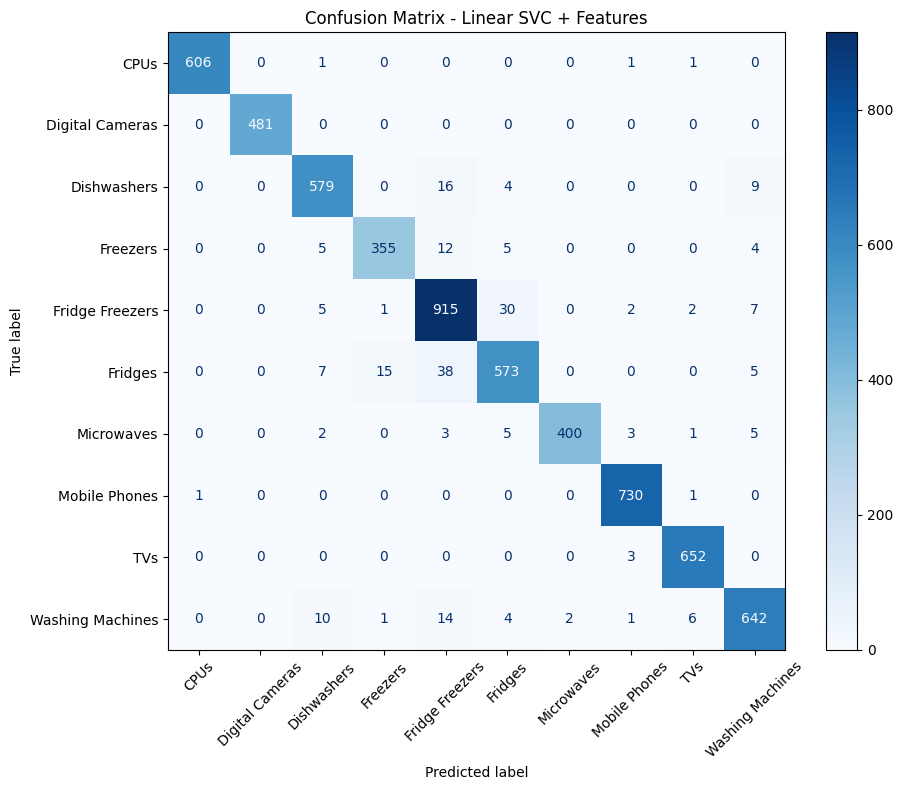

In [44]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

final_model = enhanced_models[
    "Linear SVC + features"
]

final_predictions = enhanced_predictions[
    "Linear SVC + features"
]

cm = confusion_matrix(
    y_test,
    final_predictions,
    labels=final_model.classes_
)

fig, ax = plt.subplots(
    figsize=(10, 8)
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=final_model.classes_
).plot(
    cmap="Blues",
    values_format="d",
    ax=ax,
    xticks_rotation=45
)

ax.set_title(
    "Confusion Matrix - Linear SVC + Features"
)

plt.tight_layout()
plt.show()

In [45]:
from scipy.sparse import hstack
import pandas as pd

# ------------------------------------------------------------
# Testiranje na novim proizvodima iz zadatka
# ------------------------------------------------------------

test_products = pd.DataFrame({
    "product_title": [
        "iphone 7 32gb gold,4,3,Apple iPhone 7 32GB",
        "olympus e m10 mark iii geh use silber",
        "kenwood k20mss15 solo",
        "bosch wap28390gb 8kg 1400 spin",
        "bosch serie 4 kgv39vl31g",
        "smeg sbs8004po"
    ],
    "expected_category": [
        "Mobile Phones",
        "Digital Cameras",
        "Microwaves",
        "Washing Machines",
        "Fridge Freezers",
        "Fridge Freezers"
    ]
})

# Iste numericke karakteristike kao u treningu
test_products["title_length"] = (
    test_products["product_title"].str.len()
)

test_products["word_count"] = (
    test_products["product_title"]
    .str.split()
    .str.len()
)

test_products["digit_count"] = (
    test_products["product_title"]
    .str.count(r"\d")
)

test_products["special_char_count"] = (
    test_products["product_title"]
    .str.count(r"[^A-Za-z0-9\s]")
)

test_products["longest_word_length"] = (
    test_products["product_title"]
    .apply(
        lambda text: max(
            len(word)
            for word in text.split()
        )
    )
)

# TF-IDF transformacija
test_text_tfidf = tfidf.transform(
    test_products["product_title"]
)

# Numericke karakteristike
test_numeric = scaler.transform(
    test_products[numeric_features]
)

# Spajanje teksta i numerickih karakteristika
test_combined = hstack([
    test_text_tfidf,
    test_numeric
]).tocsr()

# Predikcija
test_products["predicted_category"] = (
    final_model.predict(test_combined)
)

# Provera da li je predikcija tacna
test_products["correct"] = (
    test_products["expected_category"]
    ==
    test_products["predicted_category"]
)

display(
    test_products[
        [
            "product_title",
            "expected_category",
            "predicted_category",
            "correct"
        ]
    ]
)

,product_title,expected_category,predicted_category,correct
0,"iphone 7 32gb gold,4,3,Apple iPhone 7 32GB",Mobile Phones,Mobile Phones,True
1,olympus e m10 mark iii geh use silber,Digital Cameras,Digital Cameras,True
2,kenwood k20mss15 solo,Microwaves,Microwaves,True
3,bosch wap28390gb 8kg 1400 spin,Washing Machines,Washing Machines,True
4,bosch serie 4 kgv39vl31g,Fridge Freezers,Fridge Freezers,True
5,smeg sbs8004po,Fridge Freezers,Dishwashers,False


In [46]:
# ------------------------------------------------------------
# Dodatni eksperiment: character-level TF-IDF
# ------------------------------------------------------------

char_tfidf = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    min_df=2,
    max_features=30000
)

X_train_char = char_tfidf.fit_transform(
    X_train["product_title"]
)

X_test_char = char_tfidf.transform(
    X_test["product_title"]
)

print("Character TF-IDF trening:")
print(X_train_char.shape)

print("\nCharacter TF-IDF test:")
print(X_test_char.shape)

Character TF-IDF trening:
(24657, 30000)

Character TF-IDF test:
(6165, 30000)


In [47]:
# ------------------------------------------------------------
# Spajanje word TF-IDF + character TF-IDF + numeric features
# ------------------------------------------------------------

X_train_full = hstack([
    X_train_text,
    X_train_char,
    X_train_numeric
]).tocsr()

X_test_full = hstack([
    X_test_text,
    X_test_char,
    X_test_numeric
]).tocsr()

print("Finalna trening matrica:")
print(X_train_full.shape)

print("\nFinalna test matrica:")
print(X_test_full.shape)

Finalna trening matrica:
(24657, 55517)

Finalna test matrica:
(6165, 55517)


In [48]:
# ------------------------------------------------------------
# Linear SVC sa svim karakteristikama
# ------------------------------------------------------------

final_candidate_model = LinearSVC()

final_candidate_model.fit(
    X_train_full,
    y_train
)

final_candidate_predictions = final_candidate_model.predict(
    X_test_full
)

final_candidate_accuracy = accuracy_score(
    y_test,
    final_candidate_predictions
)

final_candidate_macro_f1 = f1_score(
    y_test,
    final_candidate_predictions,
    average="macro"
)

final_candidate_weighted_f1 = f1_score(
    y_test,
    final_candidate_predictions,
    average="weighted"
)

print("Linear SVC - word + char + numeric features")
print("Accuracy:", round(final_candidate_accuracy, 4))
print("Macro F1:", round(final_candidate_macro_f1, 4))
print("Weighted F1:", round(final_candidate_weighted_f1, 4))

print("\nClassification report:")
print(
    classification_report(
        y_test,
        final_candidate_predictions,
        digits=4
    )
)

Linear SVC - word + char + numeric features
Accuracy: 0.9888
Macro F1: 0.9889
Weighted F1: 0.9888

Classification report:
                  precision    recall  f1-score   support

            CPUs     0.9984    0.9951    0.9967       609
 Digital Cameras     1.0000    1.0000    1.0000       481
     Dishwashers     0.9967    0.9934    0.9951       608
        Freezers     0.9789    0.9738    0.9763       381
 Fridge Freezers     0.9854    0.9813    0.9833       962
         Fridges     0.9536    0.9671    0.9603       638
      Microwaves     0.9976    0.9857    0.9916       419
   Mobile Phones     0.9959    0.9973    0.9966       732
             TVs     0.9954    0.9985    0.9970       655
Washing Machines     0.9898    0.9941    0.9919       680

        accuracy                         0.9888      6165
       macro avg     0.9892    0.9886    0.9889      6165
    weighted avg     0.9889    0.9888    0.9888      6165



c:\python314\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


In [49]:
# ------------------------------------------------------------
# Ponovno testiranje 6 proizvoda sa unapredjenim modelom
# ------------------------------------------------------------

test_char = char_tfidf.transform(
    test_products["product_title"]
)

test_full = hstack([
    test_text_tfidf,
    test_char,
    test_numeric
]).tocsr()

test_products["predicted_category_final"] = (
    final_candidate_model.predict(test_full)
)

test_products["correct_final"] = (
    test_products["expected_category"]
    ==
    test_products["predicted_category_final"]
)

display(
    test_products[
        [
            "product_title",
            "expected_category",
            "predicted_category_final",
            "correct_final"
        ]
    ]
)

,product_title,expected_category,predicted_category_final,correct_final
0,"iphone 7 32gb gold,4,3,Apple iPhone 7 32GB",Mobile Phones,Mobile Phones,True
1,olympus e m10 mark iii geh use silber,Digital Cameras,Digital Cameras,True
2,kenwood k20mss15 solo,Microwaves,Microwaves,True
3,bosch wap28390gb 8kg 1400 spin,Washing Machines,Washing Machines,True
4,bosch serie 4 kgv39vl31g,Fridge Freezers,Fridge Freezers,True
5,smeg sbs8004po,Fridge Freezers,Dishwashers,False


In [50]:
# ------------------------------------------------------------
# Analiza problema: SMEG / SBS naslovi
# ------------------------------------------------------------

for term in ["smeg", "sbs", "sbs8004po"]:

    matches = df_model[
        df_model["product_title"]
        .str.contains(
            term,
            case=False,
            na=False
        )
    ]

    print("=" * 70)
    print("PRETRAGA:", term)
    print("Broj pronadjenih proizvoda:", len(matches))

    if len(matches) > 0:

        print("\nKategorije:")
        print(
            matches["category"]
            .value_counts()
        )

        print("\nPrimeri:")
        display(
            matches[
                ["product_title", "category"]
            ].head(20)
        )

PRETRAGA: smeg
Broj pronadjenih proizvoda: 1270

Kategorije:
category
Fridge Freezers     405
Fridges             392
Dishwashers         246
Washing Machines     98
Freezers             70
Microwaves           59
Name: count, dtype: int64

Primeri:


,product_title,category
14852,smeg sf4309mx 45cm height classic dark glass c...,Microwaves
14853,smeg classic integrated microwave oven in stai...,Microwaves
14855,smeg sf4309mx 60cm classic microwave grill for...,Microwaves
14856,smeg sf4309mx stainless steel compact microwav...,Microwaves
14864,smeg sc445mx 60cm cucina built in microwave fo...,Microwaves
14865,smeg cucina integrated microwave oven in stain...,Microwaves
14866,smeg cucina compact sc445mx 45cm height built ...,Microwaves
14867,smeg sc445mx cucina 45cm high microwave oven w...,Microwaves
14868,smeg sc445mx cucina stainless steel compact mi...,Microwaves
14914,smeg fmi320x classic 21l stainless steel and e...,Microwaves


PRETRAGA: sbs
Broj pronadjenih proizvoda: 66

Kategorije:
category
Fridge Freezers    64
Mobile Phones       2
Name: count, dtype: int64

Primeri:


,product_title,category
1031,sbs s.p.a. tescreen4dsas8pk 4d glass screen pr...,Mobile Phones
2843,samsung sbs tescreensas8 galaxy s8 1piece s sc...,Mobile Phones
27208,bosch k hlger t solitaire american sbs frenchd...,Fridge Freezers
27358,samsung rf24hsesbsr sparkling water american s...,Fridge Freezers
27359,samsung rf24hsesbsr multi door fridge freezer ...,Fridge Freezers
27360,samsung rf24hsesbsr fridge freezer american st...,Fridge Freezers
27363,samsung rf24hsesbsr freestanding 495l a stainl...,Fridge Freezers
27364,samsung rf24hsesbsr french style 4 door fridge...,Fridge Freezers
27365,samsung rf24hsesbsr 4 door usa fridge freezer,Fridge Freezers
27366,samsung rf24hsesbsr,Fridge Freezers


PRETRAGA: sbs8004po
Broj pronadjenih proizvoda: 2

Kategorije:
category
Fridge Freezers    2
Name: count, dtype: int64

Primeri:


,product_title,category
30746,smeg fridges and freezers sbs8004po 230 240 v,Fridge Freezers
30747,smeg sbs8004po fridge freezer,Fridge Freezers


In [51]:
# ------------------------------------------------------------
# HIBRIDNA PREDIKCIJA
# Model code lookup + ML model
# ------------------------------------------------------------

import re
from collections import Counter


def extract_model_codes(text):
    """
    Pronalazi duze alfanumericke oznake koje sadrze
    i slova i brojeve, npr:
    sbs8004po, kgv39vl31g, wap28390gb
    """

    tokens = re.findall(
        r"\b[a-zA-Z0-9]+\b",
        text.lower()
    )

    codes = []

    for token in tokens:
        has_letter = any(
            char.isalpha()
            for char in token
        )

        has_digit = any(
            char.isdigit()
            for char in token
        )

        if (
            len(token) >= 6
            and has_letter
            and has_digit
        ):
            codes.append(token)

    return codes


def predict_product_category(title):

    # --------------------------------------------------------
    # 1. Provera model-koda u trening podacima
    # --------------------------------------------------------

    codes = extract_model_codes(title)

    for code in codes:

        matches = df_model[
            df_model["product_title"]
            .str.contains(
                code,
                case=False,
                na=False,
                regex=False
            )
        ]

        if len(matches) > 0:

            category_counts = (
                matches["category"]
                .value_counts()
            )

            # Koristimo lookup samo kada postoji jasan konsenzus.
            top_category = category_counts.index[0]
            top_count = category_counts.iloc[0]

            if (
                top_count / len(matches) >= 0.80
            ):
                return top_category, "model-code lookup"

    # --------------------------------------------------------
    # 2. Ako nema jasnog model-koda, koristi ML model
    # --------------------------------------------------------

    temp = pd.DataFrame({
        "product_title": [title]
    })

    temp["title_length"] = (
        temp["product_title"].str.len()
    )

    temp["word_count"] = (
        temp["product_title"]
        .str.split()
        .str.len()
    )

    temp["digit_count"] = (
        temp["product_title"]
        .str.count(r"\d")
    )

    temp["special_char_count"] = (
        temp["product_title"]
        .str.count(r"[^A-Za-z0-9\s]")
    )

    temp["longest_word_length"] = (
        temp["product_title"]
        .apply(
            lambda text: max(
                len(word)
                for word in text.split()
            )
        )
    )

    word_features = tfidf.transform(
        temp["product_title"]
    )

    char_features = char_tfidf.transform(
        temp["product_title"]
    )

    numeric_features_new = scaler.transform(
        temp[numeric_features]
    )

    combined_features = hstack([
        word_features,
        char_features,
        numeric_features_new
    ]).tocsr()

    prediction = final_candidate_model.predict(
        combined_features
    )[0]

    return prediction, "Linear SVC"

In [52]:
hybrid_results = []

for _, row in test_products.iterrows():

    prediction, method = predict_product_category(
        row["product_title"]
    )

    hybrid_results.append({
        "product_title": row["product_title"],
        "expected_category": row["expected_category"],
        "predicted_category": prediction,
        "method": method,
        "correct": (
            prediction
            ==
            row["expected_category"]
        )
    })

hybrid_results_df = pd.DataFrame(
    hybrid_results
)

display(hybrid_results_df)

,product_title,expected_category,predicted_category,method,correct
0,"iphone 7 32gb gold,4,3,Apple iPhone 7 32GB",Mobile Phones,Mobile Phones,Linear SVC,True
1,olympus e m10 mark iii geh use silber,Digital Cameras,Digital Cameras,Linear SVC,True
2,kenwood k20mss15 solo,Microwaves,Microwaves,model-code lookup,True
3,bosch wap28390gb 8kg 1400 spin,Washing Machines,Washing Machines,model-code lookup,True
4,bosch serie 4 kgv39vl31g,Fridge Freezers,Fridge Freezers,model-code lookup,True
5,smeg sbs8004po,Fridge Freezers,Fridge Freezers,model-code lookup,True


In [53]:
# ------------------------------------------------------------
# VALIDNA EVALUACIJA HIBRIDNOG SISTEMA
# Lookup se gradi SAMO iz trening podataka
# ------------------------------------------------------------

from collections import defaultdict, Counter


# Spajamo naslove trening skupa sa njihovim kategorijama
train_lookup_data = pd.DataFrame({
    "product_title": X_train["product_title"],
    "category": y_train
})


# Gradimo mapu: model-code -> kategorije koje se pojavljuju uz taj kod
code_categories = defaultdict(list)

for _, row in train_lookup_data.iterrows():

    codes = extract_model_codes(
        row["product_title"]
    )

    for code in codes:
        code_categories[code].append(
            row["category"]
        )


# Zadrzavamo samo kodove kod kojih postoji jasan konsenzus
model_code_lookup = {}

for code, categories in code_categories.items():

    counts = Counter(categories)

    top_category, top_count = counts.most_common(1)[0]

    confidence = top_count / len(categories)

    # Najmanje 2 pojavljivanja i minimum 80% iste kategorije
    if len(categories) >= 2 and confidence >= 0.80:

        model_code_lookup[code] = top_category


print(
    "Broj pouzdanih model-code pravila:",
    len(model_code_lookup)
)

Broj pouzdanih model-code pravila: 3949


In [54]:
# ------------------------------------------------------------
# Hibridna predikcija na TEST skupu
# ------------------------------------------------------------

hybrid_test_predictions = []

for i, title in enumerate(
    X_test["product_title"]
):

    prediction = None

    codes = extract_model_codes(title)

    # Prvo proveravamo lookup naucen SAMO na trening skupu
    for code in codes:

        if code in model_code_lookup:
            prediction = model_code_lookup[code]
            break

    # Ako nema poznatog koda, koristimo Linear SVC
    if prediction is None:
        prediction = final_candidate_predictions[i]

    hybrid_test_predictions.append(
        prediction
    )


hybrid_accuracy = accuracy_score(
    y_test,
    hybrid_test_predictions
)

hybrid_macro_f1 = f1_score(
    y_test,
    hybrid_test_predictions,
    average="macro"
)

hybrid_weighted_f1 = f1_score(
    y_test,
    hybrid_test_predictions,
    average="weighted"
)


print("Hibridni sistem - TEST skup")
print(
    "Accuracy:",
    round(hybrid_accuracy, 4)
)
print(
    "Macro F1:",
    round(hybrid_macro_f1, 4)
)
print(
    "Weighted F1:",
    round(hybrid_weighted_f1, 4)
)

Hibridni sistem - TEST skup
Accuracy: 0.9885
Macro F1: 0.9885
Weighted F1: 0.9885
